# 03 · Surrogate models

This notebook covers Phase 4: machine-learning models that predict the fate of a second moon from
its starting parameters alone, and the probability of each outcome.

1. Task, data and validation
2. Feature sets (rule P1)
3. Baselines, including a physics rule
4. Model comparison (rules P2 and P3)
5. Errors and the rare class (rule P4)
6. Calibration (rule P6)
7. Chaos as the limit (rule P5)
8. What the model learned
9. Would more simulations help?
10. Predicting when a system fails
11. The selected model and the Phase 5 criteria

The notebook loads saved results; the computations live in `src/` (`train_models.py`,
`analyze_models.py`, `plot_models.py`). All results use the 9,600 training systems: the 2,400
test systems remain untouched until Phase 5. Terms are defined in
[`docs/glossary.md`](../docs/glossary.md).

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd

import plot_models as figs
from features import config, training_data
from horizons import ROOT

phase4 = ROOT / "data" / "phase4"
decisions = json.loads((phase4 / "decisions.json").read_text())
analysis = json.loads((ROOT / "data" / "phase4_analysis.json").read_text())
selected = json.loads((ROOT / "configs" / "selected_model.json").read_text())
fs = decisions["P1"]["chosen"]


def run(key):
    return json.loads((phase4 / f"{key}.json").read_text())

## 1. Task, data and validation

**Target.** Four classes: `survived` (100 years), `ejected`, `hit_earth`, and `moon_interaction`,
which merges collisions with the Moon and loss of the Moon. Both are close encounters with the
Moon in the same region of parameter space, and together they give 254 training examples instead
of 137 and 117. The probability of `survived` also gives a binary survival prediction.

**Validation.** Stratified 5-fold cross-validation on the training systems. Hyperparameters are
chosen by a randomized search inside each training part (nested cross-validation), so every system
receives one out-of-fold prediction from a model that never saw it. All comparisons use paired
bootstrap intervals over these predictions. Decision rules P1 to P6 were fixed before any model
was trained.

In [2]:
df = training_data()
counts = df["y"].value_counts().sort_index()
pd.DataFrame({"class": config()["classes"], "systems": counts.to_numpy(),
              "share": (counts / len(df)).map("{:.1%}".format).to_numpy()})

,class,systems,share
0,survived,3643,37.9%
1,ejected,3073,32.0%
2,hit_earth,2630,27.4%
3,moon_interaction,254,2.6%


## 2. Feature sets (rule P1)

Three input sets were compared with a Random Forest at fixed default settings:

- **F1, orbital elements:** log mass, log semi-major axis, eccentricity, cos *i*, and the three
  orientation angles as sine and cosine pairs.
- **F2, state vectors:** the Earth-relative position and velocity, and log mass.
- **F3, elements plus physics:** F1 with periapsis and apoapsis, a flag for orbits crossing the
  Moon's, |cos *i*|, the Lidov–Kozai quantity √(1−e²) cos *i*, and the starting angle to the Moon.

**Rule P1:** F2 or F3 replaces F1 only if the bootstrap interval of its macro-F1 gain lies above
zero.

In [3]:
for name in ("F1", "F2", "F3"):
    print(f"{name}: macro-F1 {run(f'rf_default_{name}')['metrics']['macro_f1']:.3f}")
for name, gain in decisions["P1"]["gains_over_F1"].items():
    print(f"{name} minus F1: {gain['mean']:+.4f} (95% {gain['interval'][0]:+.4f} to {gain['interval'][1]:+.4f})")
print("Chosen:", fs)

F1: macro-F1 0.651
F2: macro-F1 0.565
F3: macro-F1 0.657
F2 minus F1: -0.0859 (95% -0.0990 to -0.0732)
F3 minus F1: +0.0063 (95% +0.0001 to +0.0141)
Chosen: F3


**Result.** State vectors are clearly worse than orbital elements (−0.086): the same orbit is far
easier to learn from its elements than from raw positions and velocities. The physics features
add a small but consistent gain (+0.006, interval just above zero), so F3 is used.

## 3. Baselines

Two baselines frame the results: always predicting the most common class, and a **physics rule**,
a decision tree of depth at most 3 that may only use the apoapsis and |cos *i*|, the two
quantities Phase 3 identified. It is the kind of rule a physicist could write down.

In [4]:
print(decisions["physics_rule_text"])

|--- apoapsis_lunar <= 0.875
|   |--- abs_cos_i <= 0.423
|   |   |--- abs_cos_i <= 0.352
|   |   |   |--- class: hit_earth
|   |   |--- abs_cos_i >  0.352
|   |   |   |--- class: hit_earth
|   |--- abs_cos_i >  0.423
|   |   |--- apoapsis_lunar <= 0.641
|   |   |   |--- class: survived
|   |   |--- apoapsis_lunar >  0.641
|   |   |   |--- class: survived
|--- apoapsis_lunar >  0.875
|   |--- apoapsis_lunar <= 1.894
|   |   |--- abs_cos_i <= 0.354
|   |   |   |--- class: hit_earth
|   |   |--- abs_cos_i >  0.354
|   |   |   |--- class: ejected
|   |--- apoapsis_lunar >  1.894
|   |   |--- apoapsis_lunar <= 2.767
|   |   |   |--- class: ejected
|   |   |--- apoapsis_lunar >  2.767
|   |   |   |--- class: ejected



**Result.** The tree rediscovers the Phase 3 picture without being told: orbits that stay inside
about 0.88 lunar distances survive unless they are near-polar (|cos *i*| ≤ 0.42, inclination
roughly 65° to 115°), in which case they collide with Earth; orbits reaching farther are ejected,
or collide with Earth when near-polar. It reaches macro-F1 0.597 and accuracy 79.5%, but never
predicts the `moon_interaction` class.

## 4. Model comparison (rules P2 and P3)

Logistic regression, Random Forest, XGBoost and a neural network (multilayer perceptron) were
tuned and evaluated with nested cross-validation on F3.

**Rule P2:** the model with the highest macro-F1 is selected, unless a simpler model's gap to it
has an interval that includes zero. **Rule P3:** the selected model must beat the physics rule in
balanced accuracy (interval above zero). The dashed line in the accuracy panel is the chaos
reference: the share of systems whose outcome does not change when nudged by 1 m (Section 7).

Selected by P2: random_forest
P3 gain over the physics rule: +0.116 (95% +0.102 to +0.131)


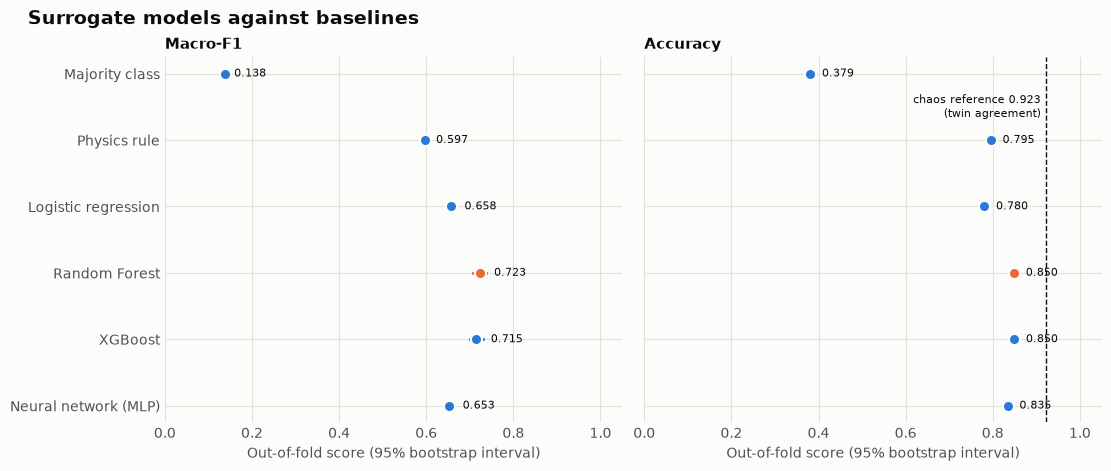

In [5]:
figs.model_comparison(analysis, fs);
p2, p3 = decisions["P2"], decisions["P3"]
print(f"Selected by P2: {p2['selected']}")
print(f"P3 gain over the physics rule: {p3['mean']:+.3f} (95% {p3['interval'][0]:+.3f} to {p3['interval'][1]:+.3f})")

**Result.** The Random Forest has the highest macro-F1 (0.723) and accuracy (85.0%); its gain over
logistic regression is clearly positive, so rule P2 selects it. XGBoost is nearly as good (0.715).
The neural network trails, as is common for small tabular datasets. The Random Forest beats the
physics rule by 0.116 in balanced accuracy (rule P3 met), mainly by recognizing part of the
`moon_interaction` class and refining the boundaries.

## 5. Errors and the rare class (rule P4)

**Rule P4:** if the recall of `moon_interaction` is below 30%, targeted sampling near the Moon's
orbit is recommended for the next phase.

moon_interaction recall 30.3% (95% 25.0% to 36.2%); collisions with the Moon 14.6%, Moon lost 48.7%
Targeted sampling recommended: False


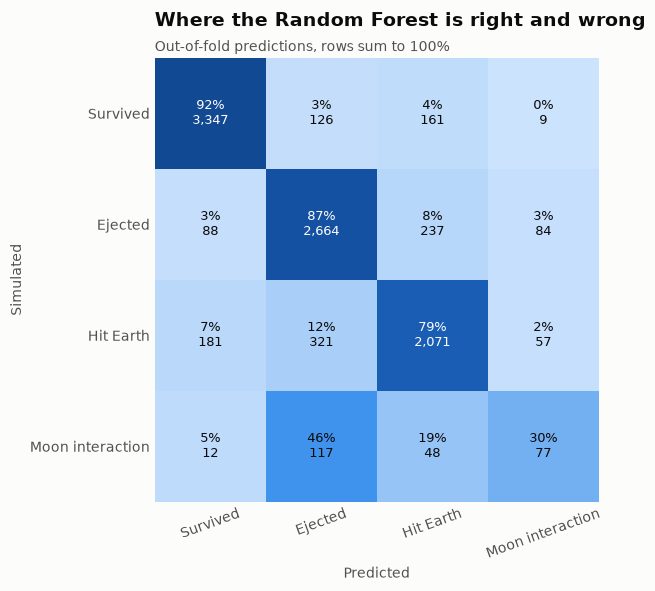

In [6]:
res = run(f"{p2['selected']}_{fs}")
oof = pd.read_csv(phase4 / f"{p2['selected']}_{fs}_oof.csv")
y, prob = oof["y"].to_numpy(), oof.filter(like="p").to_numpy()
figs.confusion(y, prob.argmax(axis=1), [figs.LABELS[c] for c in config()["classes"]],
               "Where the Random Forest is right and wrong", "Out-of-fold predictions, rows sum to 100%");
p4 = analysis["P4"]
print(f"moon_interaction recall {p4['recall']:.1%} (95% {p4['interval'][0]:.1%} to {p4['interval'][1]:.1%}); "
      f"collisions with the Moon {p4['sub_recall']['hit_moon']:.1%}, Moon lost {p4['sub_recall']['moon_lost']:.1%}")
print("Targeted sampling recommended:", p4["targeted_sampling_recommended"])

**Result.** Survivors are recognized in 92% of cases, ejections in 87% and collisions with Earth in
79%; most errors are confusions between ejection and collision with Earth. The `moon_interaction`
recall is 30.3%, just above the 30% criterion (interval 25% to 36%), so targeted sampling is not
triggered; this is a near miss. Losses of the Moon are found far more often (48.7%) than
collisions with it (14.6%), and 46% of all `moon_interaction` systems are predicted as
ejections.

## 6. Calibration (rule P6)

A predicted survival probability is useful only if it is honest: systems given 70% should survive
about 70% of the time. **Rule P6:** if the expected calibration error (ECE) of P(survived) exceeds
0.05, an isotonic-calibrated version is evaluated.

ECE 0.019; binary survival accuracy 93.8%, ROC AUC 0.985


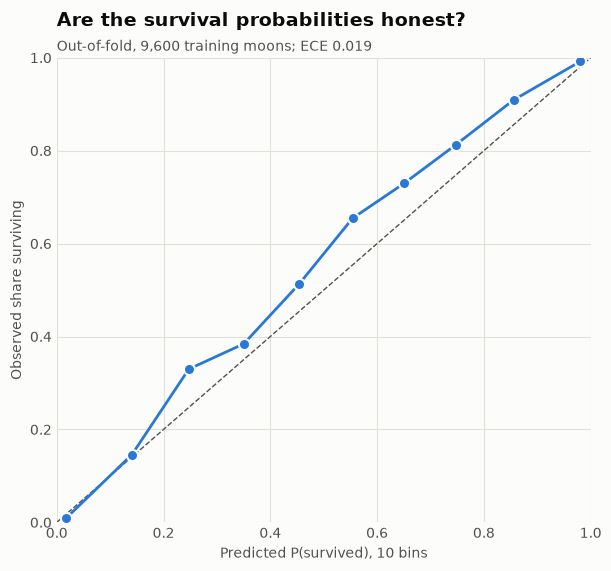

In [7]:
figs.calibration_plot(y, prob, res["metrics"]["survived_ece"]);
m = res["metrics"]
print(f"ECE {m['survived_ece']:.3f}; binary survival accuracy {m['survived_accuracy']:.1%}, ROC AUC {m['survived_auc']:.3f}")

**Result.** The probabilities are well calibrated (ECE 0.019), so no calibration step is needed. In
the middle range the model is slightly cautious: observed survival is a little above the
prediction. As a binary survival classifier it reaches 93.8% accuracy and a ROC AUC of 0.985.

## 7. Chaos as the limit (rule P5)

1,500 random training systems were simulated a second time with the second moon displaced by
1 m (`configs/twins_1m.json`). The share of pairs with the same outcome is the chaos reference;
pairs with different outcomes mark systems whose fate is decided by chaos. **Rule P5:** model
errors are concentrated on chaotic systems if the error rate on them exceeds that on stable
systems (interval above zero).

Twin agreement: 92.3% (4 classes), 98.4% (survived or not)
Model error on chaotic systems 53.4% (116), on stable systems 10.5%; difference 95% +0.336 to +0.522


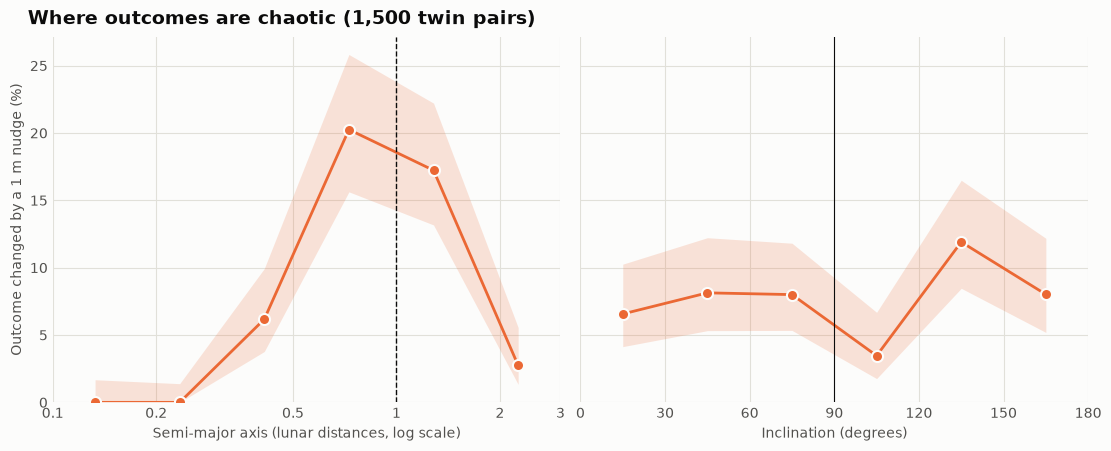

In [8]:
figs.chaos_profile(analysis);
c, p5 = analysis["chaos"], analysis["P5"]
print(f"Twin agreement: {c['agreement']:.1%} (4 classes), {c['binary_agreement']:.1%} (survived or not)")
print(f"Model error on chaotic systems {p5['error_chaotic']:.1%} ({p5['chaotic_moons']}), "
      f"on stable systems {p5['error_stable']:.1%}; difference 95% "
      f"{p5['difference_interval'][0]:+.3f} to {p5['difference_interval'][1]:+.3f}")

**Result.** A 1 m nudge changes the outcome of 7.7% of systems (agreement 92.3%; 98.4% for survival
alone). Chaos peaks near the Moon's orbit, where 20% of outcomes change between 0.55 and 0.97 lunar
distances, and is absent inside 0.31 lunar distances. Rule P5 is met: the model is wrong on 53.4% of chaotic systems but only 10.5%
of stable ones. On systems whose outcome is not changed by the nudge, it is right 89.5% of the
time, close to the 92.3% agreement between twins. The remaining errors are largely where even the
simulation cannot give a reproducible answer.

## 8. What the model learned

**Grouped permutation importance:** the drop in macro-F1 when a group of related inputs is shuffled
together. The predicted survival probability is also compared with the simulated stability map.

Largest difference in a map cell: 0.134


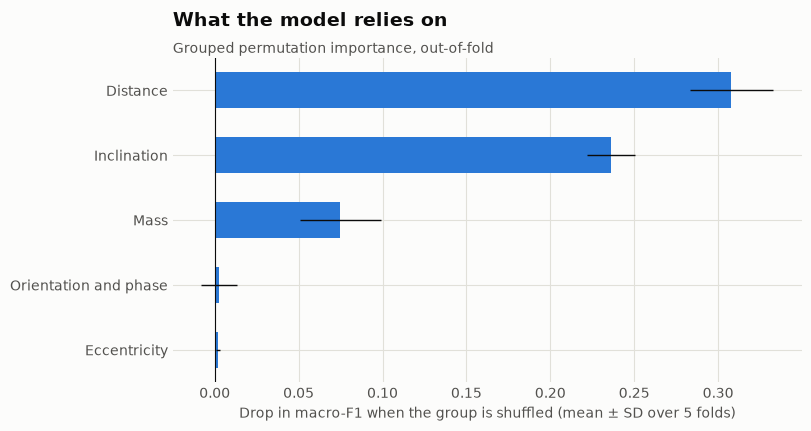

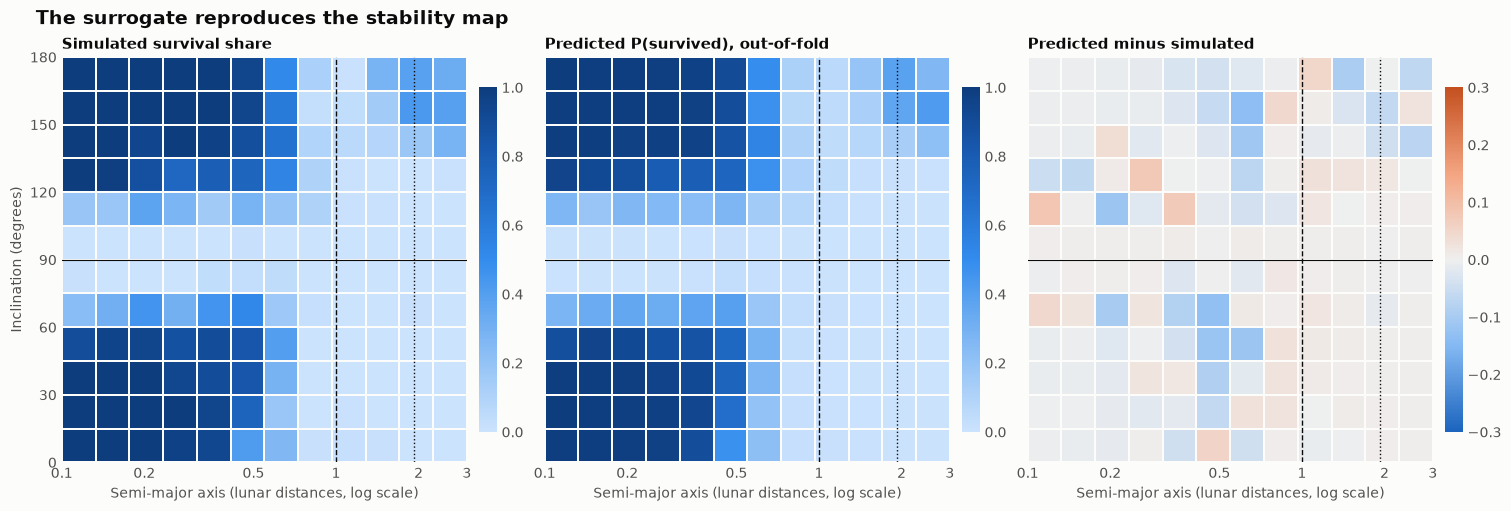

In [9]:
figs.importance_plot(analysis);
fig, worst = figs.predicted_map(df, oof)
print(f"Largest difference in a map cell: {worst:.3f}")

**Result.** The model relies on distance (semi-major axis, periapsis, apoapsis and the crossing
flag) and inclination (cos *i*, |cos *i*| and the Lidov–Kozai quantity), the two drivers found in
Phase 3, followed by mass. Eccentricity on its own adds almost nothing, because periapsis and
apoapsis in the distance group already carry it; the orientation angles do not matter. The
predicted map reproduces the simulated one: the largest cell difference is 0.13, at the edges of
the survival regions.

## 9. Would more simulations help?

The selected model was retrained on 10% to 100% of each training part, with each fold's tuned
settings.

   768 systems: macro-F1 0.700, moon_interaction recall 29.1%
  1536 systems: macro-F1 0.704, moon_interaction recall 27.9%
  3072 systems: macro-F1 0.711, moon_interaction recall 28.3%
  5376 systems: macro-F1 0.716, moon_interaction recall 28.7%
  7680 systems: macro-F1 0.723, moon_interaction recall 30.3%


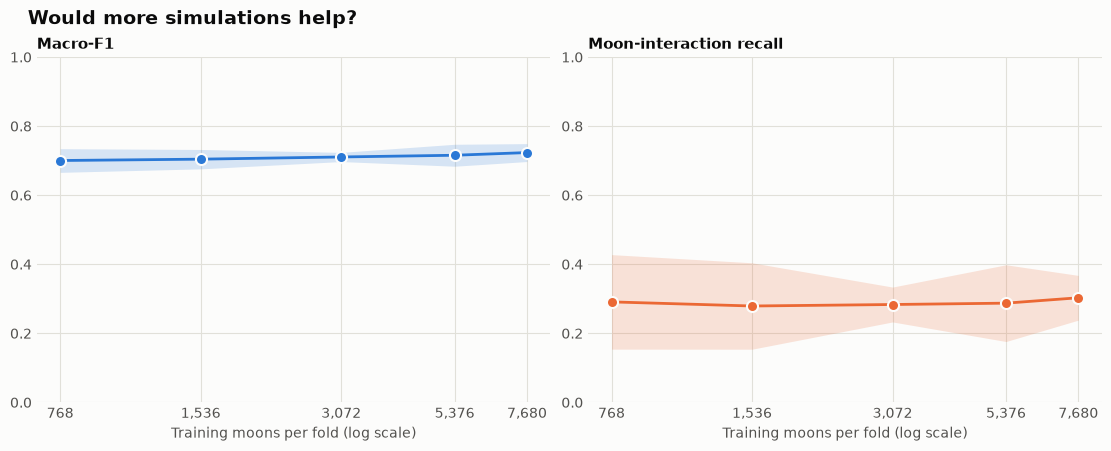

In [10]:
figs.learning_curve_plot(analysis);
for point in analysis["learning_curve"]:
    print(f"{point['moons']:6.0f} systems: macro-F1 {point['macro_f1'][0]:.3f}, "
          f"moon_interaction recall {point['rare_recall'][0]:.1%}")

**Result.** Ten times more data raises macro-F1 only from 0.700 to 0.723, and the
`moon_interaction` recall stays near 30%. The curve is nearly flat: the model is limited by the
chaotic nature of the outcomes rather than by the number of simulations.

## 10. Predicting when a system fails

A secondary task predicts the lifetime class: lost within 1 year, within 1 to 10 years, within 10
to 100 years, or surviving 100 years. Survivors form the last class, so their unknown true
lifetimes are not guessed.

macro-F1 0.728, accuracy 76.7%, within one class 98.6% (majority class: 37.9%)


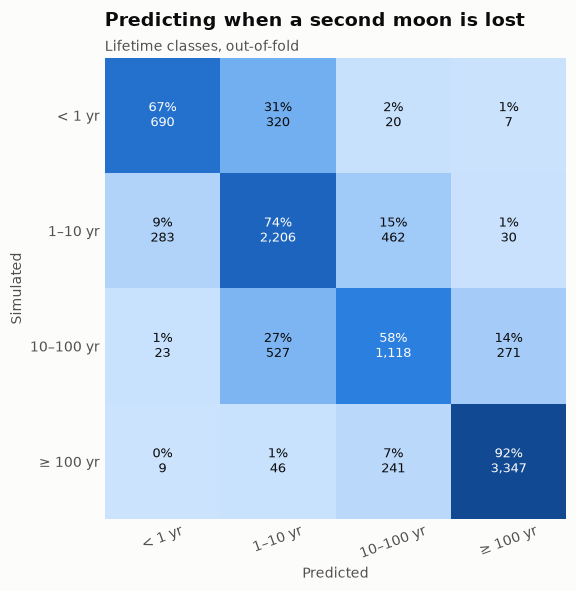

In [11]:
life = run(f"lifetime_{p2['selected']}_{fs}")
life_oof = pd.read_csv(phase4 / f"lifetime_{p2['selected']}_{fs}_oof.csv")
figs.confusion(life_oof["y"].to_numpy(), life_oof.filter(like="p").to_numpy().argmax(axis=1), figs.LIFETIME,
               "Predicting when a second moon is lost", "Lifetime classes, out-of-fold");
print(f"macro-F1 {life['metrics']['macro_f1']:.3f}, accuracy {life['metrics']['accuracy']:.1%}, "
      f"within one class {life['within_one_bin']:.1%} (majority class: 37.9%)")

**Result.** The lifetime class is predicted with 76.7% accuracy (macro-F1 0.728), and 98.6% of
predictions are correct or one class off. The starting conditions therefore determine not only
whether a second moon is lost but, roughly, when.

## 11. The selected model and the Phase 5 criteria

The final settings come from one randomized search on all 9,600 training systems. The criteria for
the single evaluation on the test set were fixed here, before the test set is opened.

In [12]:
print(json.dumps({k: selected[k] for k in ("model", "feature_set", "params", "calibrate")}, indent=1))
print(json.dumps(selected["phase5_criteria"], indent=1))

{
 "model": "random_forest",
 "feature_set": "F3",
 "params": {
  "min_samples_leaf": 5,
  "max_features": 0.5,
  "max_depth": 20,
  "class_weight": "balanced_subsample"
 },
 "calibrate": false
}
{
 "fixed_on": "end of Phase 4, before the test set is opened",
 "test_set": "2,400 moons in configs/split.json, evaluated once",
 "C1_generalization": {
  "metric": "test macro-F1",
  "criterion": "inside the cross-validated 95% interval",
  "interval": [
   0.7084237355082573,
   0.7368932705087219
  ]
 },
 "C2_beats_physics_rule": {
  "metric": "balanced accuracy",
  "criterion": "paired bootstrap interval of the gain over the physics rule above 0 on the test set"
 },
 "C3_calibration": {
  "metric": "ECE of P(survived)",
  "criterion": "at most 0.05"
 },
 "C4_rare_class": {
  "metric": "moon_interaction recall",
  "criterion": "reported with a Wilson interval (descriptive)"
 },
 "speedup": {
  "metric": "median prediction time per moon versus median simulation time (1.456 s per moon, confi

## Summary

- A Random Forest on orbital elements plus physics features predicts the outcome with macro-F1
  0.723 and accuracy 85.0%, against 0.597 and 79.5% for a physics rule and 37.9% for always
  predicting survival. Its survival probabilities are well calibrated (ECE 0.019; ROC AUC 0.985).
- Errors concentrate on chaotic systems: on systems unaffected by a 1 m nudge the model is right
  89.5% of the time, close to the 92.3% reproducibility of the simulation itself.
- Distance and inclination dominate the predictions, as the physics of Phase 3 suggests.
- More simulations would help little; the rare `moon_interaction` class stays hard (recall 30%).
- The lifetime class is predicted to within one class 98.6% of the time.

The feature set was chosen on the same training data, which makes these cross-validated scores
slightly optimistic; the single test-set evaluation in Phase 5 gives the unbiased estimate.
It confirmed them: test macro-F1 0.711 and accuracy 85.1% (notebook 04).